# Model Training — Rating Classification
**Anggota 2 | TF-IDF + Multinomial Naive Bayes + Linear SVM + Random Forest**

Notebook ini melatih dan membandingkan tiga model untuk memprediksi `label` dari `content_clean` pada `data/Rating_labeled_processed.csv`. Pemisahan data utama menggunakan `GroupShuffleSplit` berdasarkan `duplicate_group` untuk mengurangi kebocoran teks duplikat.

**Catatan penting:**
- Ubah `DATA_PATH` jika lokasi CSV berbeda.
- Notebook mengasumsikan kolom `label`, `content_clean`, `duplicate_group`, `app`, dan `n_apps_in_group` tersedia. Jika nama kolom aplikasi berbeda, ubah `APP_COL`.
- Untuk 600K baris, TF-IDF + Random Forest dapat memakan waktu dan memori besar. Notebook menggunakan batas fitur dan subset train opsional agar eksperimen awal tetap dapat dijalankan.
- `class_weight='balanced'` didukung oleh Linear SVM dan Random Forest, tetapi **MultinomialNB tidak memiliki parameter `class_weight`**. Untuk Naive Bayes, gunakan `fit(..., sample_weight=...)` sebagai pendekatan penyeimbangan kelas.

## 1. Instalasi dan import library

In [4]:
# Jalankan jika library belum tersedia
# %pip install -U pandas numpy scipy scikit-learn matplotlib seaborn joblib

import os
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, f1_score
)
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

## 2. Konfigurasi

In [5]:
DATA_PATH = Path("../data/Rating_labeled_processed.csv")
DATA_GZ_PATH = Path("../data/Rating_labeled_processed.csv.gz")
DATA_SOURCE = DATA_PATH if DATA_PATH.exists() else DATA_GZ_PATH

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

TEXT_COL = "content_clean"       # alternatif: content_clean_stopword
TARGET_COL = "label"
GROUP_COL = "duplicate_group"
APP_COL = "app"                  # ubah jika kolom aplikasi bernama lain
N_APPS_COL = "n_apps_in_group"

TEST_SIZE = 0.20
MAX_FEATURES = 200_000           # turunkan ke 100_000 jika RAM terbatas
MIN_DF = 2
MAX_DF = 0.98
N_JOBS = -1

# Jika RAM/waktu terbatas, tetapkan misalnya 150_000.
# None = gunakan seluruh data.
MAX_ROWS = None

print("Data source:", DATA_SOURCE.resolve())
print("Data:", DATA_PATH.resolve())
print("Model output:", MODEL_DIR.resolve())

Data source: D:\kuliah\Semester 7\ML\government-app-sentiment-analysis\data\Rating_labeled_processed.csv.gz
Data: D:\kuliah\Semester 7\ML\government-app-sentiment-analysis\data\Rating_labeled_processed.csv
Model output: D:\kuliah\Semester 7\ML\government-app-sentiment-analysis\notebooks\models


## 3. Baca data dan validasi kolom

In [6]:
if not DATA_PATH.exists() and not DATA_GZ_PATH.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {DATA_PATH.resolve()} atau {DATA_GZ_PATH.resolve()}\n"
        "Pastikan notebook dijalankan dari root project atau ubah DATA_PATH."
    )

if DATA_SOURCE.suffix == ".gz":
    df = pd.read_csv(DATA_SOURCE, compression="gzip", low_memory=False)
else:
    df = pd.read_csv(DATA_SOURCE, low_memory=False)

print("Ukuran awal:", df.shape)
print("Kolom:", df.columns.tolist())

required = [TEXT_COL, TARGET_COL, GROUP_COL]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing}")

if APP_COL not in df.columns:
    print(f"PERINGATAN: kolom aplikasi '{APP_COL}' tidak ditemukan. "
          "Eksperimen LOAO tidak dapat dijalankan sebelum APP_COL disesuaikan.")

# Buang baris tanpa target, teks, atau group ID
df = df.dropna(subset=[TEXT_COL, TARGET_COL, GROUP_COL]).copy()
df[TEXT_COL] = df[TEXT_COL].astype(str).str.strip()
df[TARGET_COL] = df[TARGET_COL].astype(str).str.strip()
df[GROUP_COL] = df[GROUP_COL].astype(str)

df = df[df[TEXT_COL].ne("") & df[TARGET_COL].ne("")]
df = df.reset_index(drop=True)

if MAX_ROWS is not None and len(df) > MAX_ROWS:
    # Subset reproducible untuk uji pipeline; bukan hasil final penelitian.
    df = df.sample(n=MAX_ROWS, random_state=RANDOM_STATE).reset_index(drop=True)
    print("PERINGATAN: memakai subset untuk eksperimen awal.")

print("Ukuran setelah pembersihan:", df.shape)
display(df.head())

Ukuran awal: (609900, 12)
Kolom: ['review_id', 'app', 'content_original', 'content_clean', 'content_clean_stopword', 'score', 'label', 'at', 'duplicate_group', 'group_size', 'has_label_conflict', 'n_apps_in_group']
Ukuran setelah pembersihan: (609900, 12)


,review_id,app,content_original,content_clean,content_clean_stopword,score,label,at,duplicate_group,group_size,has_label_conflict,n_apps_in_group
0,0,satusehat,Lelet....,lelet,lelet,1,Negative,2021-10-14 06:05:05,0,157,True,5
1,1,satusehat,Josss,joss,joss,5,Positive,2021-10-14 06:04:17,1,561,True,6
2,2,satusehat,Jadi lebih waspada sama bahaya covid 19,jadi lebih waspada sama bahaya covid 19,jadi lebih waspada sama bahaya covid 19,5,Positive,2021-10-14 06:02:30,2,1,False,1
3,3,satusehat,Saya sudah vaksin kedua tapi sertifikat vaksin...,saya sudah vaksin kedua tapi sertifikat vaksin...,vaksin kedua tapi sertifikat vaksin tidak kelu...,2,Negative,2021-10-14 06:02:24,3,1,False,1
4,4,satusehat,Mantap...sangat membantu,mantap sangat membantu,mantap sangat membantu,5,Positive,2021-10-14 06:01:28,4,345,True,6


## 4. Eksplorasi distribusi label dan aplikasi

Distribusi label:


,jumlah
label,
Positive,329707
Negative,246033
Neutral,34160


,persentase
label,
Positive,54.06
Negative,40.34
Neutral,5.60


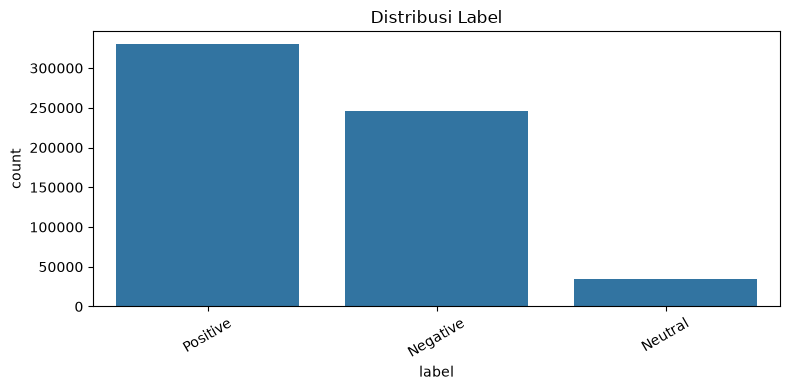

Jumlah duplicate_group: 353798
Distribusi jumlah ulasan per aplikasi:


,jumlah
app,
JMO,197216
satusehat,188100
mobileJKN,120497
pertamina,95494
KAI,7285
BMKG,1308


Distribusi n_apps_in_group:


,jumlah
n_apps_in_group,
1,353477
2,17464
3,15664
4,32363
5,27874
6,163058


In [7]:
print("Distribusi label:")
display(df[TARGET_COL].value_counts().rename("jumlah").to_frame())
display((df[TARGET_COL].value_counts(normalize=True) * 100)
        .round(2).rename("persentase").to_frame())

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x=TARGET_COL, order=df[TARGET_COL].value_counts().index)
plt.title("Distribusi Label")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Jumlah duplicate_group:", df[GROUP_COL].nunique())
if APP_COL in df.columns:
    print("Distribusi jumlah ulasan per aplikasi:")
    display(df[APP_COL].value_counts(dropna=False).to_frame("jumlah"))
if N_APPS_COL in df.columns:
    print("Distribusi n_apps_in_group:")
    display(df[N_APPS_COL].value_counts(dropna=False).sort_index().to_frame("jumlah"))

## 5. GroupShuffleSplit untuk data utama

Pemisahan dilakukan berdasarkan `duplicate_group`, bukan baris individual. Dengan begitu, satu grup duplikat tidak sengaja masuk ke train sekaligus test.

Catatan: `GroupShuffleSplit` tidak menjamin proporsi label sama persis seperti stratified split. Setelah split, periksa distribusi label dan apakah semua kelas ada di train.

In [8]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)
train_idx, test_idx = next(
    splitter.split(df, y=df[TARGET_COL], groups=df[GROUP_COL])
)

train_df = df.iloc[train_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

train_groups = set(train_df[GROUP_COL])
test_groups = set(test_df[GROUP_COL])
overlap = train_groups.intersection(test_groups)

print(f"Train: {len(train_df):,} baris")
print(f"Test : {len(test_df):,} baris")
print(f"Group overlap: {len(overlap)} (seharusnya 0)")
assert len(overlap) == 0, "Kebocoran group ditemukan!"

print("\nDistribusi label train:")
display(train_df[TARGET_COL].value_counts().to_frame("jumlah"))
print("\nDistribusi label test:")
display(test_df[TARGET_COL].value_counts().to_frame("jumlah"))

Train: 488,458 baris
Test : 121,442 baris
Group overlap: 0 (seharusnya 0)

Distribusi label train:


,jumlah
label,
Positive,263622
Negative,197192
Neutral,27644



Distribusi label test:


,jumlah
label,
Positive,66085
Negative,48841
Neutral,6516


## 6. TF-IDF Unigram + Bigram

In [9]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=MAX_FEATURES,
    min_df=MIN_DF,
    max_df=MAX_DF,
    sublinear_tf=True,
    strip_accents="unicode",
    dtype=np.float32
)

# FIT hanya pada data train, lalu transform test
X_train = vectorizer.fit_transform(train_df[TEXT_COL])
X_test = vectorizer.transform(test_df[TEXT_COL])
y_train = train_df[TARGET_COL].to_numpy()
y_test = test_df[TARGET_COL].to_numpy()

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("Jumlah fitur:", len(vectorizer.get_feature_names_out()))

X_train: (488458, 200000)
X_test : (121442, 200000)
Jumlah fitur: 200000


## 7. Fungsi evaluasi

In [10]:
results = []
trained_models = {}

def evaluate_model(name, model, X_eval, y_true, split_name="holdout"):
    y_pred = model.predict(X_eval)
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)

    results.append({
        "split": split_name,
        "model": name,
        "accuracy": accuracy,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1
    })

    print(f"\n=== {name} | {split_name} ===")
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Macro F1  : {macro_f1:.4f}")
    print(f"Weighted F1: {weighted_f1:.4f}")
    print("\nClassification report:")
    print(classification_report(y_true, y_pred, zero_division=0))
    return y_pred

## 8. Training tiga model

- **Multinomial Naive Bayes:** menggunakan `sample_weight` yang dihitung dari bobot kelas karena `MultinomialNB` tidak menyediakan `class_weight`.
- **Linear SVM:** menggunakan `SGDClassifier(loss='hinge', class_weight='balanced')`.
- **Random Forest:** menggunakan `class_weight='balanced_subsample'`. Model ini dapat sangat berat pada data TF-IDF besar; jika terlalu lama, jalankan subset eksperimen dahulu atau kurangi `MAX_FEATURES`.

In [11]:
# Bobot sampel untuk menyeimbangkan kelas pada MultinomialNB
nb_sample_weight = compute_sample_weight(class_weight="balanced", y=y_train)

# 8A. Multinomial Naive Bayes
start = time.time()
nb_model = MultinomialNB(alpha=0.5)
nb_model.fit(X_train, y_train, sample_weight=nb_sample_weight)
print(f"Naive Bayes selesai dalam {time.time() - start:.1f} detik")
trained_models["MultinomialNB"] = nb_model
nb_pred = evaluate_model("MultinomialNB", nb_model, X_test, y_test)

# 8B. Linear SVM via SGDClassifier
start = time.time()
svm_model = SGDClassifier(
    loss="hinge",
    class_weight="balanced",
    max_iter=20,
    tol=1e-3,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS
)
svm_model.fit(X_train, y_train)
print(f"Linear SVM selesai dalam {time.time() - start:.1f} detik")
trained_models["LinearSVM_SGD"] = svm_model
svm_pred = evaluate_model("LinearSVM_SGD", svm_model, X_test, y_test)

# 8C. Random Forest
start = time.time()
rf_model = RandomForestClassifier(
    n_estimators=150,
    class_weight="balanced_subsample",
    max_features="sqrt",
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS
)
rf_model.fit(X_train, y_train)
print(f"Random Forest selesai dalam {time.time() - start:.1f} detik")
trained_models["RandomForest"] = rf_model
rf_pred = evaluate_model("RandomForest", rf_model, X_test, y_test)

Naive Bayes selesai dalam 1.6 detik

=== MultinomialNB | holdout ===
Accuracy  : 0.8051
Macro F1  : 0.6556
Weighted F1: 0.8343

Classification report:
              precision    recall  f1-score   support

    Negative       0.87      0.78      0.82     48841
     Neutral       0.17      0.45      0.24      6516
    Positive       0.95      0.86      0.90     66085

    accuracy                           0.81    121442
   macro avg       0.66      0.70      0.66    121442
weighted avg       0.88      0.81      0.83    121442

Linear SVM selesai dalam 2.2 detik

=== LinearSVM_SGD | holdout ===
Accuracy  : 0.8680
Macro F1  : 0.6340
Weighted F1: 0.8541

Classification report:
              precision    recall  f1-score   support

    Negative       0.81      0.95      0.87     48841
     Neutral       0.26      0.07      0.12      6516
    Positive       0.94      0.89      0.91     66085

    accuracy                           0.87    121442
   macro avg       0.67      0.64      0.63   

## 9. Perbandingan hasil dan confusion matrix

,split,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,holdout,MultinomialNB,0.805133,0.661217,0.697751,0.655563,0.834338
2,holdout,RandomForest,0.840294,0.651291,0.661904,0.655009,0.845213
1,holdout,LinearSVM_SGD,0.867962,0.669187,0.636547,0.633976,0.854134


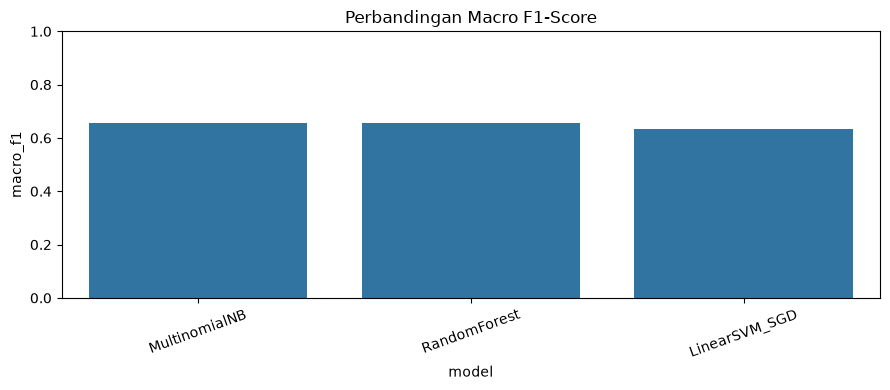

Model terbaik berdasarkan Macro F1: MultinomialNB


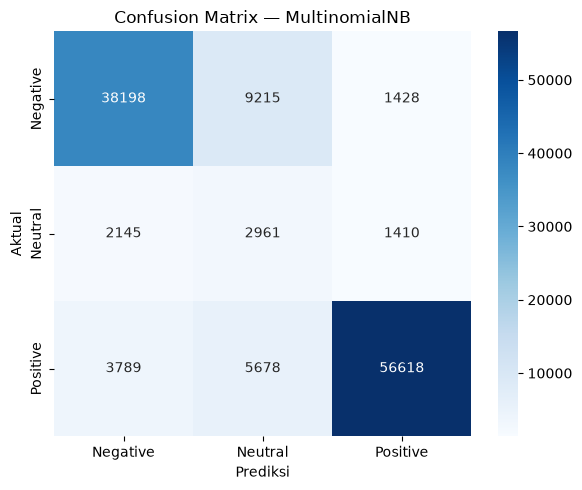

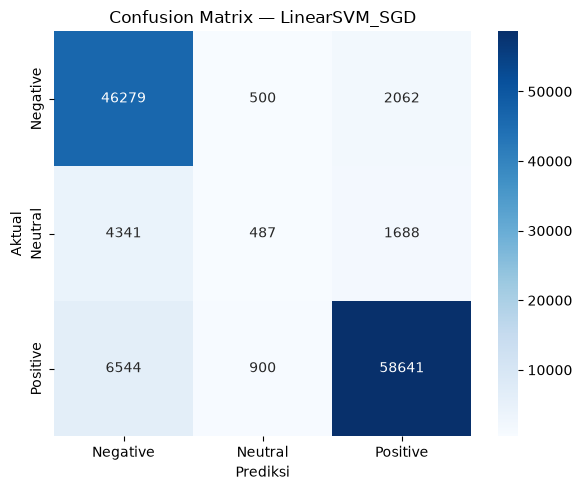

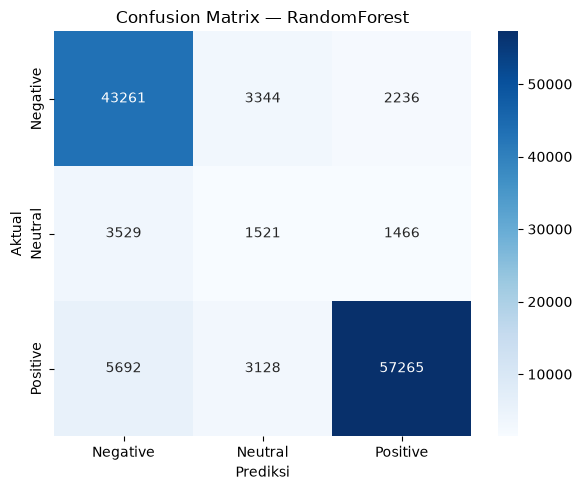

In [12]:
results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False)
display(results_df)

plt.figure(figsize=(9, 4))
sns.barplot(data=results_df, x="model", y="macro_f1")
plt.title("Perbandingan Macro F1-Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

best_name = results_df.iloc[0]["model"]
print("Model terbaik berdasarkan Macro F1:", best_name)

predictions = {
    "MultinomialNB": nb_pred,
    "LinearSVM_SGD": svm_pred,
    "RandomForest": rf_pred
}
labels = sorted(pd.Series(y_test).unique())

for name, pred in predictions.items():
    cm = confusion_matrix(y_test, pred, labels=labels)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Prediksi")
    plt.ylabel("Aktual")
    plt.tight_layout()
    plt.show()

## 10. Eksperimen Leave-One-App-Out (LOAO)

Latih model pada lima aplikasi dan uji pada satu aplikasi yang ditinggalkan. Ulangi untuk setiap aplikasi.

**Catatan penting tentang duplikasi lintas aplikasi:** untuk uji transfer domain murni, evaluasi subset test dengan `n_apps_in_group == 1`. Namun, agar grup duplikat tidak bocor ke train dan test dalam satu fold, semua baris dengan `duplicate_group` yang muncul pada aplikasi target dikeluarkan dari data train fold. Ini membuat evaluasi lebih ketat dan menghindari teks identik lintas aplikasi masuk ke kedua sisi.

Eksperimen ini menggunakan TF-IDF yang di-fit ulang hanya pada data train di setiap fold. Untuk efisiensi, kode menggunakan Linear SVM sebagai model LOAO utama; bila dibutuhkan, ulangi dengan model lain.

In [13]:
def run_loao(data, app_col=APP_COL, text_col=TEXT_COL, target_col=TARGET_COL,
             group_col=GROUP_COL, n_apps_col=N_APPS_COL, max_features=MAX_FEATURES):
    if app_col not in data.columns:
        raise ValueError(f"Kolom aplikasi '{app_col}' tidak ada. Ubah APP_COL.")
    apps = sorted(data[app_col].dropna().astype(str).unique())
    loao_rows = []

    for target_app in apps:
        print(f"\n===== LOAO: test app = {target_app} =====")
        target_mask = data[app_col].astype(str).eq(target_app)
        fold_test = data[target_mask].copy()
        other_apps = data[~target_mask].copy()

        # Buang dari train semua group yang ada di test app.
        target_groups = set(fold_test[group_col].astype(str))
        fold_train = other_apps[
            ~other_apps[group_col].astype(str).isin(target_groups)
        ].copy()

        if fold_train.empty or fold_test.empty:
            print("Fold dilewati karena train/test kosong.")
            continue

        # Fit vectorizer hanya pada train fold
        fold_vectorizer = TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=max_features,
            min_df=MIN_DF,
            max_df=MAX_DF,
            sublinear_tf=True,
            strip_accents="unicode",
            dtype=np.float32
        )
        Xtr = fold_vectorizer.fit_transform(fold_train[text_col].astype(str))
        Xte = fold_vectorizer.transform(fold_test[text_col].astype(str))
        ytr = fold_train[target_col].astype(str).to_numpy()
        yte = fold_test[target_col].astype(str).to_numpy()

        fold_model = SGDClassifier(
            loss="hinge",
            class_weight="balanced",
            max_iter=20,
            tol=1e-3,
            random_state=RANDOM_STATE,
            n_jobs=N_JOBS
        )
        fold_model.fit(Xtr, ytr)
        pred = fold_model.predict(Xte)

        p, r, mf1, _ = precision_recall_fscore_support(
            yte, pred, average="macro", zero_division=0
        )
        row = {
            "target_app": target_app,
            "train_rows": len(fold_train),
            "test_rows": len(fold_test),
            "accuracy": accuracy_score(yte, pred),
            "macro_precision": p,
            "macro_recall": r,
            "macro_f1": mf1
        }

        # Transfer domain murni: hanya group yang muncul di satu aplikasi
        if n_apps_col in fold_test.columns:
            pure = fold_test[pd.to_numeric(
                fold_test[n_apps_col], errors="coerce"
            ).eq(1)].copy()
            row["pure_test_rows_n_apps_eq_1"] = len(pure)
            if len(pure) > 0:
                Xpure = fold_vectorizer.transform(pure[text_col].astype(str))
                ypure = pure[target_col].astype(str).to_numpy()
                ppred = fold_model.predict(Xpure)
                row["pure_macro_f1_n_apps_eq_1"] = f1_score(
                    ypure, ppred, average="macro", zero_division=0
                )
            else:
                row["pure_macro_f1_n_apps_eq_1"] = np.nan

        loao_rows.append(row)
        print(f"Train={len(fold_train):,}, Test={len(fold_test):,}, "
              f"Macro F1={mf1:.4f}")

    return pd.DataFrame(loao_rows)

# Jalankan saat model holdout selesai.
# LOAO dapat memerlukan waktu cukup lama karena TF-IDF di-fit ulang untuk tiap aplikasi.
loao_results = run_loao(df)
display(loao_results)
loao_results.to_csv(MODEL_DIR / "loao_results.csv", index=False)


===== LOAO: test app = BMKG =====
Train=440,126, Test=1,308, Macro F1=0.5104

===== LOAO: test app = JMO =====
Train=272,758, Test=197,216, Macro F1=0.6232

===== LOAO: test app = KAI =====
Train=415,776, Test=7,285, Macro F1=0.6018

===== LOAO: test app = mobileJKN =====
Train=299,174, Test=120,497, Macro F1=0.6289

===== LOAO: test app = pertamina =====
Train=308,073, Test=95,494, Macro F1=0.5684

===== LOAO: test app = satusehat =====
Train=240,926, Test=188,100, Macro F1=0.6174


,target_app,train_rows,test_rows,accuracy,macro_precision,macro_recall,macro_f1,pure_test_rows_n_apps_eq_1,pure_macro_f1_n_apps_eq_1
0,BMKG,440126,1308,0.836391,0.568084,0.492306,0.510426,601,0.504622
1,JMO,272758,197216,0.895896,0.687345,0.637693,0.623151,91351,0.611370
2,KAI,415776,7285,0.784214,0.674877,0.608380,0.601773,5311,0.566489
3,mobileJKN,299174,120497,0.863706,0.693675,0.637486,0.628876,68927,0.592820
4,pertamina,308073,95494,0.825822,0.592773,0.593934,0.568387,67097,0.518044
5,satusehat,240926,188100,0.836752,0.661957,0.621649,0.617379,120190,0.571491


## 11. Simpan model terbaik dan TF-IDF vectorizer

In [14]:
# Pilih model berdasarkan Macro F1 dari eksperimen holdout
best_name = results_df.iloc[0]["model"]
best_model = trained_models[best_name]

# Bundle praktis untuk dashboard
bundle = {
    "model": best_model,
    "vectorizer": vectorizer,
    "text_column": TEXT_COL,
    "target_column": TARGET_COL,
    "model_name": best_name,
    "labels": sorted(df[TARGET_COL].astype(str).unique().tolist()),
    "metrics": results_df.iloc[0].to_dict(),
    "random_state": RANDOM_STATE
}

joblib.dump(bundle, MODEL_DIR / "rating_classifier_bundle.pkl")
joblib.dump(best_model, MODEL_DIR / "rating_best_model.pkl")
joblib.dump(vectorizer, MODEL_DIR / "rating_tfidf_vectorizer.pkl")
results_df.to_csv(MODEL_DIR / "holdout_model_comparison.csv", index=False)

print("File tersimpan:")
for path in sorted(MODEL_DIR.glob("*")):
    print("-", path)

File tersimpan:
- models\holdout_model_comparison.csv
- models\loao_results.csv
- models\rating_best_model.pkl
- models\rating_classifier_bundle.pkl
- models\rating_tfidf_vectorizer.pkl


## 12. Contoh penggunaan model tersimpan

In [15]:
# Contoh untuk Anggota 3 / dashboard:
loaded_bundle = joblib.load(MODEL_DIR / "rating_classifier_bundle.pkl")
loaded_model = loaded_bundle["model"]
loaded_vectorizer = loaded_bundle["vectorizer"]

contoh_teks = [
    "The application is useful and easy to navigate.",
    "The app keeps crashing and the service is terrible."
]
X_contoh = loaded_vectorizer.transform(contoh_teks)
prediksi = loaded_model.predict(X_contoh)

for teks, label in zip(contoh_teks, prediksi):
    print(f"Text: {teks}\nPredicted label: {label}\n")

Text: The application is useful and easy to navigate.
Predicted label: Positive

Text: The app keeps crashing and the service is terrible.
Predicted label: Positive



## 13. Catatan interpretasi dan reproducibility

1. Gunakan **Macro F1** sebagai metrik utama karena kelas `Neutral` minoritas.
2. Jangan menyimpulkan model terbaik hanya dari akurasi.
3. Laporkan jumlah baris, distribusi label, proporsi train-test, dan tidak adanya overlap `duplicate_group`.
4. Hasil dari `MAX_ROWS` yang dibatasi hanya untuk uji pipeline; eksperimen final perlu memakai seluruh data jika sumber daya memungkinkan.
5. `class_weight` tidak tersedia pada `MultinomialNB`; notebook menggunakan sample weights untuk pendekatan seimbang.
6. Random Forest pada TF-IDF berdimensi tinggi bisa sangat lambat dan memerlukan RAM besar. Jika gagal, catat kendala komputasi dan pertimbangkan eksperimen subset untuk debugging, bukan mengganti diam-diam hasil final.
7. Simpan versi Python dan scikit-learn yang dipakai saat training agar model `.pkl` lebih mudah direproduksi.